# Classification Algorithms: When to Use What?

You've already learned **KNN, Decision Trees, Random Forests, Gradient Boosting, and Logistic Regression** individually. Now the big question:

> **"I have a classification problem. Which algorithm should I pick?"**

This notebook is your **go-to reference** for answering that question. We'll compare all five algorithms across the dimensions that actually matter when making that choice.

---
## 1. The One-Liner Refresher

Before we compare, let's make sure the core idea of each algorithm is crystal clear.

| Algorithm | What It Actually Does |
|-----------|----------------------|
| **KNN** | Looks at the K most similar data points and goes with the majority vote |
| **Decision Tree** | Asks a series of yes/no questions (like a flowchart) to reach a decision |
| **Random Forest** | Builds many decision trees on random subsets of data, then takes a majority vote across all trees |
| **Gradient Boosting** | Builds trees one after another — each new tree specifically tries to fix the mistakes of the previous ones |
| **Logistic Regression** | Assigns a weight to each feature, adds them up, and converts the total into a probability |

### Random Forest vs. Gradient Boosting — The Key Difference

Both use many trees, but the **strategy** is completely different:

| | Random Forest | Gradient Boosting |
|--|---------------|-------------------|
| **How trees are built** | All trees are built **independently**, in parallel | Trees are built **sequentially** — each one learns from the last |
| **What each tree focuses on** | Each tree sees a random sample of data and features | Each tree focuses on the **errors** the previous trees made |
| **Analogy** | A committee of independent experts voting | A student who reviews their wrong answers after each test and studies those topics harder |

---
## 2. Head-to-Head: Key Properties

This is the table you'll want to bookmark.

| Property | KNN | Decision Tree | Random Forest | Gradient Boosting | Logistic Regression |
|----------|-----|---------------|---------------|-------------------|---------------------|
| **Needs feature scaling?** | ✅ Yes | ❌ No | ❌ No | ❌ No | ✅ Yes |
| **Handles non-linear patterns?** | ✅ Yes | ✅ Yes | ✅ Yes | ✅ Yes | ❌ No (linear boundary) |
| **Interpretable / Explainable?** | ⚠️ Hard to explain | ✅ Very (you can visualize the tree) | ⚠️ Hard (100 trees) | ⚠️ Hard (sequential trees) | ✅ Very (coefficients tell the story) |
| **Outputs probabilities?** | ✅ Yes (proportion of neighbors) | ✅ Yes (but poorly calibrated) | ✅ Yes (well calibrated) | ✅ Yes (well calibrated) | ✅ Yes (best calibrated) |
| **Training speed** | ⚡ None (lazy learner) | ⚡ Fast | 🐢 Slower (many trees) | 🐢 Slowest (trees built one by one) | ⚡ Very fast |
| **Prediction speed** | 🐢 Slow (scans all data) | ⚡ Very fast | ⚡ Fast | ⚡ Fast | ⚡ Very fast |
| **Overfitting risk** | ⚠️ Medium (low K = overfit) | 🔴 High (without pruning) | 🟢 Low (built-in averaging) | ⚠️ Medium (can overfit if too many trees) | 🟢 Low |
| **Handles many features well?** | ❌ Struggles (curse of dimensionality) | ⚠️ OK | ✅ Yes | ✅ Yes | ✅ Yes (with regularization) |
| **Sensitive to outliers?** | ✅ Yes | ❌ Not much | ❌ Not much | ⚠️ Somewhat | ✅ Yes |
| **Handles missing values?** | ❌ No | ⚠️ Some implementations | ⚠️ Some implementations | ✅ Yes (XGBoost handles natively) | ❌ No |
| **Gives feature importance?** | ❌ No | ✅ Yes | ✅ Yes | ✅ Yes | ✅ Yes (via coefficients) |

---
## 3. Pros and Cons

### KNN — "The Crowd Follower"

| ✅ Pros | ❌ Cons |
|---------|--------|
| Dead simple to understand | Very slow at prediction time on large data |
| No training phase at all — just store the data | Must scale all features first |
| Naturally handles multi-class problems | Struggles when you have many features (curse of dimensionality) |
| Makes no assumptions about data distribution | Sensitive to irrelevant or noisy features |
| Can capture complex, local patterns | No built-in feature importance |

---

### Decision Tree — "The Flowchart"

| ✅ Pros | ❌ Cons |
|---------|--------|
| Most interpretable — you can literally draw the logic | Overfits easily without depth limits or pruning |
| No feature scaling needed | Unstable — small data changes can create a completely different tree |
| Handles both numeric and categorical features natively | Tends to create biased splits toward features with many unique values |
| Fast training and very fast predictions | Usually lower accuracy than ensemble methods |
| Easy to explain to non-technical stakeholders | Greedy algorithm — doesn't guarantee globally optimal tree |

---

### Random Forest — "The Independent Committee"

| ✅ Pros | ❌ Cons |
|---------|--------|
| Strong accuracy with very little tuning | Less interpretable — hard to visualize 100+ trees |
| Naturally resists overfitting (averaging reduces variance) | Slower to train (building many trees) |
| Handles high-dimensional data well | Uses more memory |
| Gives reliable feature importance scores | Can be overkill for simple, linear problems |
| Robust to outliers and noisy data | Doesn't improve much beyond a certain number of trees |

---

### Gradient Boosting — "The Mistake Fixer"

| ✅ Pros | ❌ Cons |
|---------|--------|
| Often the **highest accuracy** of all (Kaggle competitions' favorite) | Slowest to train (trees must be built one by one, can't parallelize) |
| Can capture very complex patterns | More hyperparameters to tune (learning rate, n_estimators, max_depth) |
| XGBoost/LightGBM implementations handle missing values natively | Can overfit if you add too many trees or set learning rate too high |
| Gives feature importance | Less interpretable than a single tree or logistic regression |
| Very strong with tabular/structured data | More sensitive to noisy data than Random Forest |

---

### Logistic Regression — "The Probability Machine"

| ✅ Pros | ❌ Cons |
|---------|--------|
| Gives well-calibrated probabilities (not just labels) | Assumes a linear decision boundary |
| Very fast to train AND predict | Cannot capture complex non-linear patterns on its own |
| Coefficients are directly interpretable ("feature X increases risk by Y") | Sensitive to outliers |
| Works great even with limited data | Needs feature scaling |
| Low risk of overfitting (especially with regularization) | Struggles when features have complex interactions |

---
## 4. When to Use Which?

This is the most important table in this notebook.

| Your Situation | Best Choice | Why |
|----------------|-------------|-----|
| You need to **explain the model** to a business audience | Decision Tree or Logistic Regression | Both are easy to present — one as a flowchart, the other as "these factors matter" |
| **Accuracy is the absolute #1 priority** | Gradient Boosting | Wins most benchmarks and competitions on tabular data |
| **Strong accuracy with minimal tuning** | Random Forest | Near-best accuracy out of the box, very forgiving |
| You need **probability scores**, not just yes/no | Logistic Regression | Best calibrated probabilities of all five |
| Your data has **complex, non-linear patterns** | Gradient Boosting or Random Forest | Both can capture non-linear boundaries; boosting often edges ahead |
| Your data has **mostly linear relationships** | Logistic Regression | Why use a complex model when a simple one works? |
| You have a **very small dataset** | KNN or Decision Tree | Both work well with limited data; KNN has no training phase |
| You have a **very large dataset** (millions of rows) | Logistic Regression, Gradient Boosting (LightGBM), or Random Forest | KNN becomes impractically slow; Decision Tree is unstable |
| You have **many features** (50+) | Gradient Boosting or Random Forest | Both handle high dimensionality well; KNN suffers |
| **Speed of prediction** matters (real-time system) | Logistic Regression or Decision Tree | Both predict in microseconds |
| You need a **quick baseline** / prototype | KNN or Logistic Regression | Minimal setup, fast results |
| You're in a **regulated industry** (healthcare, finance) | Logistic Regression or Decision Tree | Regulators often require explainable models |
| You **don't want to worry about feature scaling** | Decision Tree, Random Forest, or Gradient Boosting | Tree-based methods don't care about scale |
| Your data has **missing values** | Gradient Boosting (XGBoost/LightGBM) | Handles missing values natively without imputation |
| You **don't want to spend time tuning** | Random Forest | Works well with defaults; Gradient Boosting needs careful tuning |

---
## 5. Visual Intuition: How Each Algorithm Draws Boundaries

One of the most practical differences is **how** each algorithm separates classes. Let's visualize this with a simple 2-feature dataset.

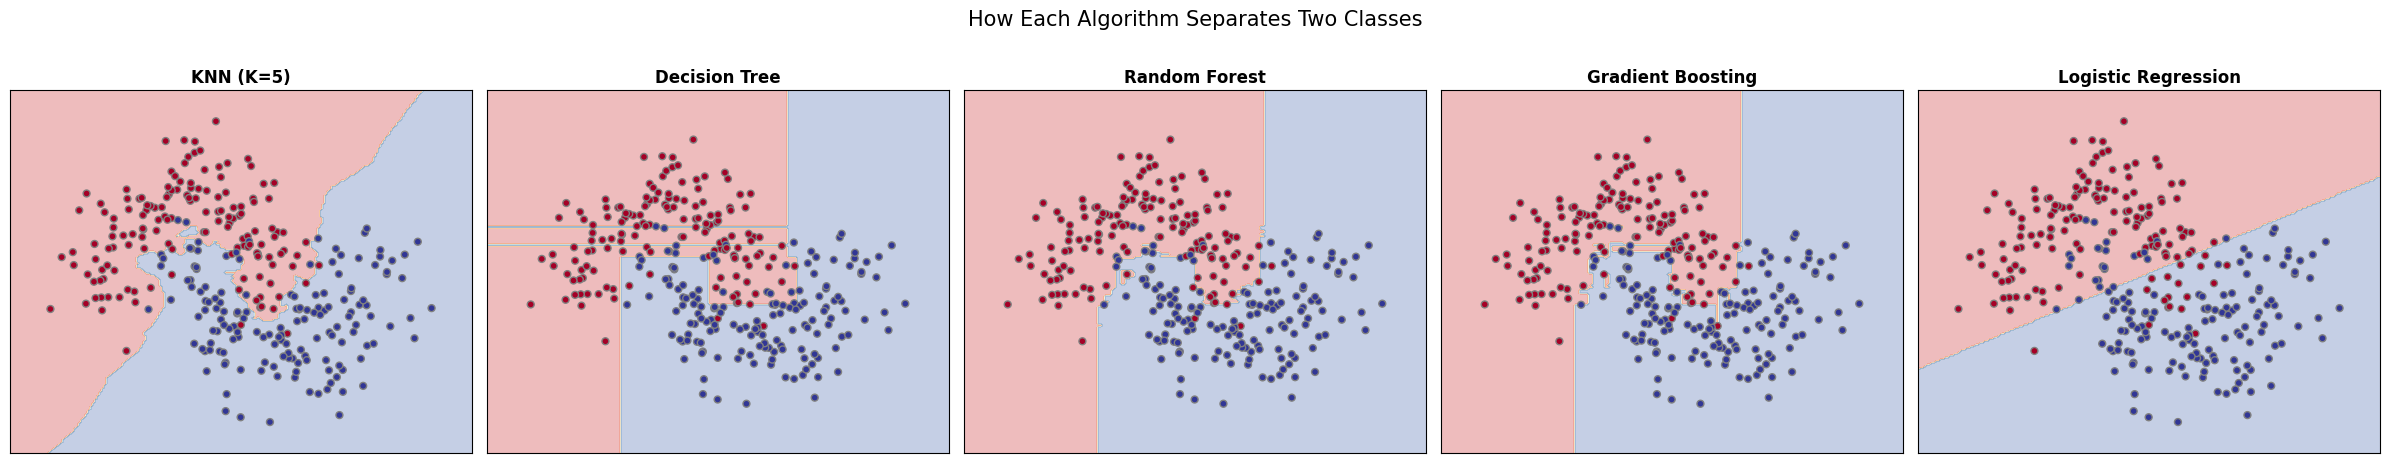

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
import warnings
warnings.filterwarnings('ignore')

# Create a non-linear dataset (two interlocking half-moons)
X, y = make_moons(n_samples=300, noise=0.25, random_state=42)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train all five models
models = {
    'KNN (K=5)': KNeighborsClassifier(n_neighbors=5).fit(X_scaled, y),
    'Decision Tree': DecisionTreeClassifier(max_depth=5, random_state=42).fit(X, y),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42).fit(X, y),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42).fit(X, y),
    'Logistic Regression': LogisticRegression().fit(X_scaled, y)
}

# Which models use scaled data?
scaled_models = {'KNN (K=5)', 'Logistic Regression'}

# Plot decision boundaries
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))

for ax, (name, model) in zip(axes, models.items()):
    use_scaled = name in scaled_models
    X_plot = X_scaled if use_scaled else X
    
    x_min, x_max = X_plot[:, 0].min() - 0.5, X_plot[:, 0].max() + 0.5
    y_min, y_max = X_plot[:, 1].min() - 0.5, X_plot[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                         np.linspace(y_min, y_max, 200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='RdYlBu')
    ax.scatter(X_plot[:, 0], X_plot[:, 1], c=y, cmap='RdYlBu', edgecolors='gray', s=25)
    ax.set_title(name, fontsize=12, fontweight='bold')
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('How Each Algorithm Separates Two Classes', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()

**What to notice:**

| Algorithm | Boundary Shape | Implication |
|-----------|---------------|-------------|
| **KNN** | Blobby, organic shapes that follow local clusters | Great for local patterns, but can be noisy |
| **Decision Tree** | Rectangular, axis-aligned boxes | It can only split on one feature at a time (horizontal or vertical cuts) |
| **Random Forest** | Smoother rectangles that blend together | Averaging many trees smooths out the jagged edges |
| **Gradient Boosting** | Smooth, refined curves — tightest fit to the true boundary | Each tree corrects errors, producing a very precise boundary |
| **Logistic Regression** | A single straight line | It can **only** draw linear boundaries — if data isn't linearly separable, it will underperform |

---
## 6. The Scaling Question

This causes a lot of confusion, so let's be very explicit.

| Algorithm | Needs Scaling? | Why? |
|-----------|---------------|------|
| **KNN** | ✅ **Must scale** | It uses distance. If feature A ranges 0–1000 and feature B ranges 0–1, KNN will basically ignore B |
| **Decision Tree** | ❌ No | It only asks "is feature > threshold?" — the actual scale doesn't matter |
| **Random Forest** | ❌ No | It's made of decision trees, same reason |
| **Gradient Boosting** | ❌ No | Also tree-based — splits don't depend on scale |
| **Logistic Regression** | ✅ **Must scale** | It assigns weights to features. Unscaled features get artificially small/large weights, confusing the optimization |

**Rule of thumb:** If the algorithm uses *distance* or *weights*, you need to scale. If it uses *splits/thresholds*, you don't.

---
## 7. The Overfitting Question

| Algorithm | Overfitting Risk | How to Control It |
|-----------|-----------------|-------------------|
| **KNN** | Medium — low K overfits, high K underfits | Tune K (try 3, 5, 7, 11...) |
| **Decision Tree** | **High** — will memorize training data if unchecked | Set `max_depth`, `min_samples_split`, `min_samples_leaf` |
| **Random Forest** | **Low** — averaging many trees cancels out individual tree overfitting | Mostly handles itself; can tune `n_estimators`, `max_depth` |
| **Gradient Boosting** | **Medium** — adding more trees can overfit | Use `learning_rate` (smaller = safer), `n_estimators`, `max_depth`, and early stopping |
| **Logistic Regression** | **Low** — simple model with few parameters | Use regularization (`C` parameter) |

### Gradient Boosting Overfitting — Why `learning_rate` Matters

Gradient Boosting has a unique control knob: the **learning rate** (also called `eta`).

| Learning Rate | What Happens |
|--------------|---------------|
| High (e.g., 0.5–1.0) | Each tree makes big corrections → learns fast but overfits fast |
| Low (e.g., 0.01–0.1) | Each tree makes small corrections → needs more trees but generalizes better |

The standard practice: **set a low learning rate (0.05–0.1) and use early stopping** to find the right number of trees automatically.

---
## 8. Quick Decision Flowchart

When you're staring at a new classification problem, follow this:

```
START
  │
  ├─ Need to EXPLAIN the model to non-technical people?
  │   ├─ Yes + data is roughly linear → Logistic Regression
  │   ├─ Yes + non-linear patterns   → Decision Tree (with max_depth)
  │   └─ No  → continue ↓
  │
  ├─ MAXIMUM ACCURACY is the top priority and you have time to tune?
  │   └─ Yes → Gradient Boosting (XGBoost / LightGBM)
  │
  ├─ Want STRONG ACCURACY with minimal effort?
  │   └─ Yes → Random Forest
  │
  ├─ Need well-calibrated PROBABILITIES?
  │   └─ Yes → Logistic Regression
  │
  ├─ Small dataset + quick prototype?
  │   └─ Yes → KNN
  │
  └─ Not sure? → Start with Random Forest (easy),
      then try Gradient Boosting (powerful).
      Compare both with Logistic Regression as a baseline.
```

---
## 9. Common Mistakes to Avoid

| Mistake | What Goes Wrong | Fix |
|---------|----------------|-----|
| Using KNN without scaling | One feature dominates distance calculations | Always `StandardScaler` before KNN |
| Decision Tree with no depth limit | Tree memorizes training data perfectly, fails on new data | Set `max_depth=3` to `7` and evaluate |
| Using Logistic Regression on highly non-linear data | Model draws a straight line through curved patterns | Switch to Random Forest / Gradient Boosting or add polynomial features |
| Gradient Boosting with too many trees and no early stopping | Model memorizes training data, test performance degrades | Always use `early_stopping_rounds` or `n_iter_no_change` |
| Gradient Boosting with high learning rate | Learns too aggressively, overfits | Use `learning_rate=0.05` to `0.1` and increase `n_estimators` |
| Picking Random Forest for every problem | Overkill for simple linear problems; wastes time and resources | If Logistic Regression gives similar accuracy, use that instead |
| Only looking at accuracy | Misleading with imbalanced classes (95% majority = 95% accuracy by predicting majority) | Always check Precision, Recall, F1, and the confusion matrix |
| Forgetting to use the same scaler on test data | Train and test data are on different scales | `.fit_transform()` on train, `.transform()` only on test |

---
## 10. Summary Card

| | KNN | Decision Tree | Random Forest | Gradient Boosting | Logistic Regression |
|---|-----|---------------|---------------|-------------------|---------------------|
| **Think of it as** | Ask your neighbors | Follow a flowchart | Vote across many independent flowcharts | Fix mistakes one tree at a time | Calculate a weighted score |
| **Best for** | Small data, quick prototype | Explainability, presenting to stakeholders | Strong accuracy with minimal tuning | Maximum accuracy on tabular data | Probabilities, linear data, speed |
| **Avoid when** | Large data, many features | You need high accuracy or stability | You need full transparency | Training time is limited; data is very noisy | Data has complex non-linear patterns |
| **Scale data?** | Yes | No | No | No | Yes |
| **Overfitting risk** | Medium | High | Low | Medium | Low |
| **Key thing to tune** | K (number of neighbors) | max_depth | n_estimators, max_depth | learning_rate, n_estimators, max_depth | C (regularization) |

---

### The Practical Pecking Order

In industry, this is a very common approach for tabular classification problems:

| Step | What to Try | Why |
|------|-------------|-----|
| 1. **Baseline** | Logistic Regression | Fast, interpretable — sets the floor for what "good" looks like |
| 2. **Easy win** | Random Forest | Usually beats the baseline with almost no tuning |
| 3. **Push for best** | Gradient Boosting (XGBoost / LightGBM) | Often squeezes out the best performance, but needs tuning |
| 4. **Explain it** | Decision Tree or Logistic Regression | When leadership asks "but *why* does the model predict this?" |

*KNN is great for learning and prototyping, but it's rarely the final model in production due to slow predictions at scale.*